MERGING IPCEI DATA TO LINKEDIN DATA


In [18]:
pip install mysql

  Obtaining dependency information for mysql from https://files.pythonhosted.org/packages/9a/52/8d29c58f6ae448a72fbc612955bd31accb930ca479a7ba7197f4ae4edec2/mysql-0.0.3-py3-none-any.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.4/91.4 kB 2.3 MB/s eta 0:00:00a 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... error
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [30 lines of output]
      /bin/sh: pkg-config: command not found
      /bin/sh: pkg-config: command not found
      /bin/sh: pkg-config: command not found
      /bin/sh: pkg-config: command not found
      Trying pkg-config --exists mysqlclient
      Command 'pkg-config --exists mysqlclient' returned non-zero exit status 127.
      Trying pkg-config --exists mariadb
      Command 'pkg-config --exists mariadb' returned non-zero exit status 127.
      Trying pkg-config --exists libmariadb
    

In [24]:
import mysql.connector

# Connect to server
cnx = mysql.connector.connect(    host='161.35.214.116',    user='mtoetzke',    passwd='Discourse-2022-ETH',    database="TweetsNet",    auth_plugin='mysql_native_password')

# Get a cursor
cur = cnx.cursor()

# Execute a query
#cur.execute("SELECT CURDATE()")

# Fetch one result
#row = cur.fetchone()
#print("Current date is: {0}".format(row[0]))

# Close connection
cnx.close()

In [8]:
#pip install pandas
#pip install matplotlib.pyplot

SyntaxError: invalid syntax (2054480387.py, line 1)

In [1]:
import os
import pandas as pd

# 📂 Set working directory
WORKING_DIR = "/Users/go82gax/Documents/Projekte/IPCEI/Analyse/Daten/LinkedIn"
os.chdir(WORKING_DIR)

# 📥 Load the IPCEI dataset
orgs_df = pd.read_csv("organizations_linkedin.csv")
collab_df = pd.read_csv("innovation_network_prepost_2020-01-01.csv")
ipcei_df = pd.read_csv("IPCEI_clean.csv")

0. Merge firm information for further inspection

In [2]:
import pandas as pd

# ✅ Step 1: Ensure the key variable "Linkedin_id" exists in both datasets
if "Linkedin_name" not in ipcei_df.columns or "Linkedin_name" not in orgs_df.columns:
    raise ValueError("Linkedin_name column is missing from one of the datasets.")

# ✅ Step 2: Merge orgs_df into ipcei_df based on Linkedin_id
ipcei_merged = ipcei_df.merge(orgs_df, on="Linkedin_name", how="left")  # Left join keeps all IPCEI firms

# ✅ Step 3: Save the merged dataset to a CSV file
file_name = "ipcei_clean_orginfo.csv"
ipcei_merged.to_csv(file_name, index=False)

print(f"✅ Merged dataset saved as {file_name}")

✅ Merged dataset saved as ipcei_clean_orginfo.csv


1. Check how many IPCEI firms can be matched to the collab data

In [3]:
import pandas as pd

# ✅ Step 1: Extract unique firms from ipcei_df
firms_with_linkedin = set(ipcei_df["Linkedin_name"].dropna().unique())

# ✅ Step 2: Extract unique firms from collab_df in "source" and "target"
firms_in_collabs = set(collabs_df["source"].dropna().unique()).union(set(orgs_df["target"].dropna().unique()))

# ✅ Step 3: Identify firms in ipcei_df that are matched in collab_df
matched_firms = firms_with_linkedin.intersection(firms_in_collabs)
unmatched_firms = firms_with_linkedin - firms_in_collabs

# ✅ Step 4: Count the number of matched and unmatched firms
matched_count = len(matched_firms)
unmatched_count = len(unmatched_firms)

# ✅ Step 5: Create a summary table
summary_df = pd.DataFrame({
    "Category": ["Matched Firms", "Unmatched Firms"],
    "Count": [matched_count, unmatched_count]
})

# 📌 Print the summary table
print(summary_df)
# 50 are not matched

# ✅ Optional: Save the summary to a CSV file
#summary_df.to_csv("matching_summary.csv", index=False)
#print("✅ Summary saved as 'matching_summary.csv'.")

# ✅ Optional: Save unmatched firms for review
#unmatched_firms_df = pd.DataFrame(unmatched_firms, columns=["Unmatched_Linkedin_name"])
#unmatched_firms_df.to_csv("unmatched_firms.csv", index=False)
#print("✅ Unmatched firms saved as 'unmatched_firms.csv'.")


KeyError: 'source'

2. Inspect and plot unique collaborations of IPCEI firms over time.

/var/folders/1w/t9ryrq_57m77f4wzbw78745m044mx9/T/ipykernel_97720/4017790719.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_collab_df["post_date"] = pd.to_datetime(filtered_collab_df["post_date"], errors="coerce")


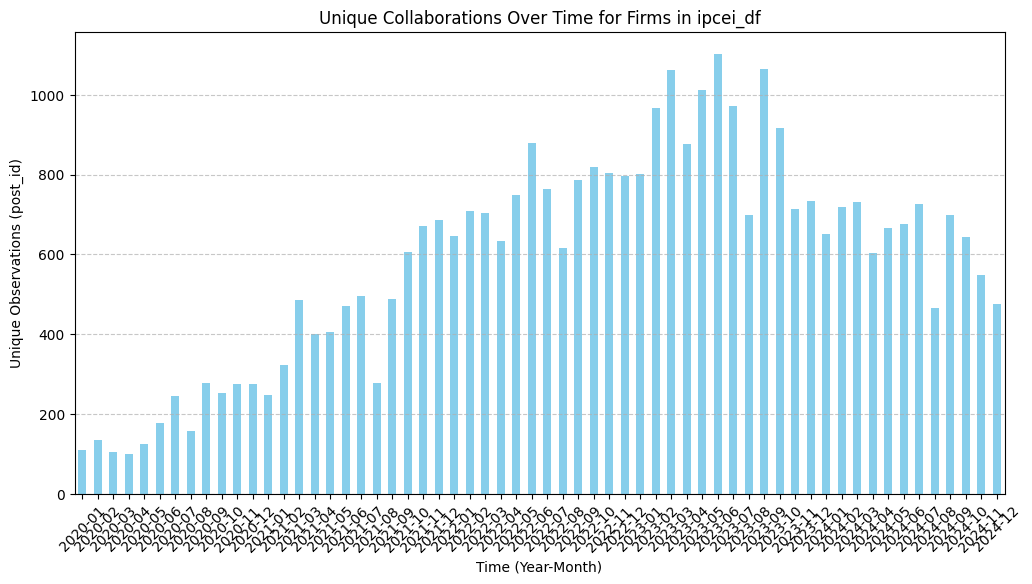

In [4]:
import matplotlib.pyplot as plt

# ✅ Step 1: Extract unique firms from ipcei_df
firms_with_linkedin = ipcei_df["Linkedin_name"].dropna().unique()

# ✅ Step 2: Filter collab_df where either "source" or "target" is in firms_with_linkedin
filtered_collab_df = collab_df[
    (collab_df["source"].isin(firms_with_linkedin)) |
    (collab_df["target"].isin(firms_with_linkedin))
]

# ✅ Step 3: Ensure "post_date" is in datetime format and remove duplicate post_ids
filtered_collab_df["post_date"] = pd.to_datetime(filtered_collab_df["post_date"], errors="coerce")

# Drop duplicate post_ids to ensure uniqueness
filtered_collab_df = filtered_collab_df.drop_duplicates(subset=["post_id"])

# ✅ Step 4: Aggregate unique post occurrences per month
unique_posts_over_time = filtered_collab_df.groupby(filtered_collab_df["post_date"].dt.to_period("M"))["post_id"].nunique()

# ✅ Step 5: Plot the unique observations over time
plt.figure(figsize=(12, 6))
unique_posts_over_time.plot(kind="bar", color="skyblue")
plt.xlabel("Time (Year-Month)")
plt.ylabel("Unique Observations (post_id)")
plt.title("Unique Collaborations Over Time for Firms in ipcei_df")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

3. Plot the development of collabs in relation to all collabs

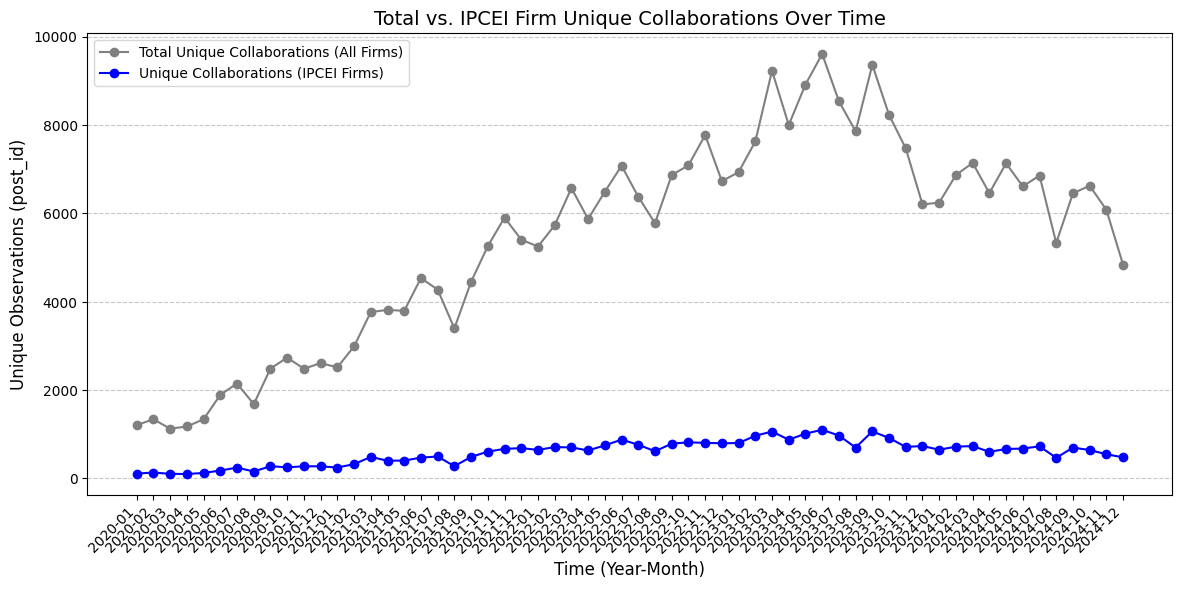

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# ✅ Step 1: Extract unique firms from ipcei_df
firms_with_linkedin = ipcei_df["Linkedin_name"].dropna().unique()

# ✅ Step 2: Filter collab_df where either "source" or "target" is in firms_with_linkedin
filtered_collab_df = collab_df[
    (collab_df["source"].isin(firms_with_linkedin)) |
    (collab_df["target"].isin(firms_with_linkedin))
].copy()

# ✅ Step 3: Convert "post_date" to datetime format and remove duplicate post_ids
collab_df["post_date"] = pd.to_datetime(collab_df["post_date"], errors="coerce")
filtered_collab_df["post_date"] = pd.to_datetime(filtered_collab_df["post_date"], errors="coerce")

# Drop duplicate post_ids to ensure uniqueness
collab_df_unique = collab_df.drop_duplicates(subset=["post_id"])
filtered_collab_df = filtered_collab_df.drop_duplicates(subset=["post_id"])

# ✅ Step 4: Aggregate unique post occurrences per month
unique_posts_all = collab_df_unique.groupby(collab_df_unique["post_date"].dt.to_period("M"))["post_id"].nunique()
unique_posts_ipcei = filtered_collab_df.groupby(filtered_collab_df["post_date"].dt.to_period("M"))["post_id"].nunique()

# ✅ Step 5: Plot both time series
plt.figure(figsize=(14, 6))

# Plot total unique collaborations (all firms)
plt.plot(unique_posts_all.index.astype(str), unique_posts_all, marker='o', linestyle='-', color='gray', label="Total Unique Collaborations (All Firms)")

# Plot unique collaborations for IPCEI firms
plt.plot(unique_posts_ipcei.index.astype(str), unique_posts_ipcei, marker='o', linestyle='-', color='blue', label="Unique Collaborations (IPCEI Firms)")

# ✅ Step 6: Improve X-axis readability
plt.xticks(rotation=45, ha='right', fontsize=10)

# Labels & title
plt.xlabel("Time (Year-Month)", fontsize=12)
plt.ylabel("Unique Observations (post_id)", fontsize=12)
plt.title("Total vs. IPCEI Firm Unique Collaborations Over Time", fontsize=14)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.7)

# ✅ Show the plot
plt.show()


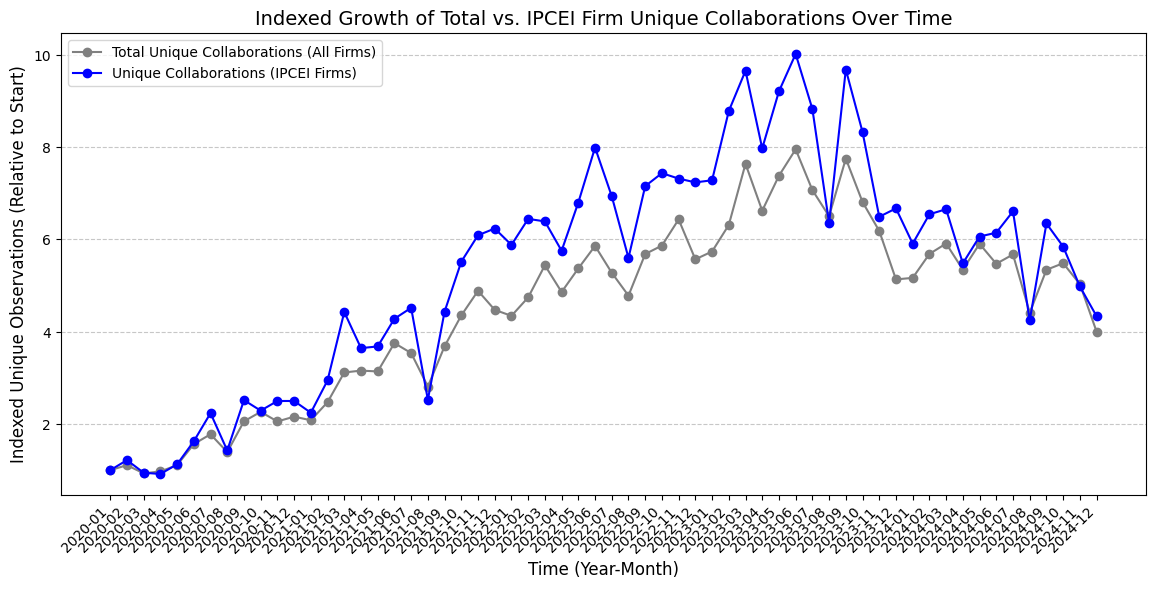

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# ✅ Step 1: Extract unique firms from ipcei_df
firms_with_linkedin = ipcei_df["Linkedin_name"].dropna().unique()

# ✅ Step 2: Filter collab_df where either "source" or "target" is in firms_with_linkedin
filtered_collab_df = collab_df[
    (collab_df["source"].isin(firms_with_linkedin)) |
    (collab_df["target"].isin(firms_with_linkedin))
].copy()

# ✅ Step 3: Convert "post_date" to datetime format and remove duplicate post_ids
collab_df["post_date"] = pd.to_datetime(collab_df["post_date"], errors="coerce")
filtered_collab_df["post_date"] = pd.to_datetime(filtered_collab_df["post_date"], errors="coerce")

# Drop duplicate post_ids to ensure uniqueness
collab_df_unique = collab_df.drop_duplicates(subset=["post_id"])
filtered_collab_df = filtered_collab_df.drop_duplicates(subset=["post_id"])

# ✅ Step 4: Aggregate unique post occurrences per month
unique_posts_all = collab_df_unique.groupby(collab_df_unique["post_date"].dt.to_period("M"))["post_id"].nunique()
unique_posts_ipcei = filtered_collab_df.groupby(filtered_collab_df["post_date"].dt.to_period("M"))["post_id"].nunique()

# ✅ Step 5: Normalize (Indexing)
unique_posts_all_indexed = unique_posts_all / unique_posts_all.iloc[0]  # Normalize to first value
unique_posts_ipcei_indexed = unique_posts_ipcei / unique_posts_ipcei.iloc[0]  # Normalize to first value

# ✅ Step 6: Plot both indexed time series
plt.figure(figsize=(14, 6))

# Plot indexed total unique collaborations (all firms)
plt.plot(unique_posts_all_indexed.index.astype(str), unique_posts_all_indexed, marker='o', linestyle='-', color='gray', label="Total Unique Collaborations (All Firms)")

# Plot indexed unique collaborations for IPCEI firms
plt.plot(unique_posts_ipcei_indexed.index.astype(str), unique_posts_ipcei_indexed, marker='o', linestyle='-', color='blue', label="Unique Collaborations (IPCEI Firms)")

# ✅ Step 7: Improve X-axis readability
plt.xticks(rotation=45, ha='right', fontsize=10)

# Labels & title
plt.xlabel("Time (Year-Month)", fontsize=12)
plt.ylabel("Indexed Unique Observations (Relative to Start)", fontsize=12)
plt.title("Indexed Growth of Total vs. IPCEI Firm Unique Collaborations Over Time", fontsize=14)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.7)

# ✅ Show the plot
plt.show()